# Анализ взаимосвязи S&P 500, Gold и DXY за пять лет с помощью классического подхода

## 0. Импорты и настройки

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.optimize import minimize
import warnings

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
warnings.filterwarnings('ignore')

## 1. Сбор и предобработка данных

### 1.1 Загрузка данных с помощью yfinance

In [3]:
tickers = {
    '^GSPC': 'S&P 500',
    'GC=F': 'Gold',
    'DX-Y.NYB': 'USD_Index'
}

In [4]:
data = yf.download(list(tickers.keys()), period='5y', interval='1d', auto_adjust=True)['Close']
data.rename(columns=tickers, inplace=True)

[*********************100%***********************]  3 of 3 completed


In [5]:
print(f"Данные загружены. Размер выборки: {data.shape}")
display(data.head(-10))

Данные загружены. Размер выборки: (1259, 3)


Ticker,USD_Index,Gold,S&P 500
Date,,,
2021-10-22,93.610001,1796.300049,NaN
2021-10-25,93.809998,1806.800049,4566.479980
2021-10-26,93.949997,1793.400024,4574.790039
2021-10-27,93.860001,1798.800049,4551.680176
2021-10-28,93.349998,1802.599976,4596.419922
...,...,...,...
2026-10-02,101.930000,4162.299805,7722.720215
2026-10-05,102.169998,4156.799805,7773.950195
2026-10-06,101.830002,4187.100098,7818.930176


### Данные успешно загружены.  Размер составляет 1259 измерений, что соотвествует ежедневным (за исключением выходных) значениям на протяжении 5 лет.

### 1.2 Проверка пропусков

In [6]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1259 entries, 2021-10-22 to 2026-10-22
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   USD_Index  1257 non-null   float64
 1   Gold       1258 non-null   float64
 2   S&P 500    1254 non-null   float64
dtypes: float64(3)
memory usage: 39.3 KB


In [7]:
data.isnull().sum()

Ticker
USD_Index    2
Gold         1
S&P 500      5
dtype: int64

In [8]:
rows_with_nan = data[data.isna().any(axis=1)]
print(rows_with_nan)

Ticker       USD_Index         Gold  S&P 500
Date                                        
2021-10-22   93.610001  1796.300049      NaN
2023-11-23         NaN  1993.300049      NaN
2025-01-09  109.180000  2690.800049      NaN
2025-05-26   98.930000          NaN      NaN
2025-07-04         NaN  3346.500000      NaN


In [9]:
mask_nan = data.isna().any(axis=1)

mask_with_neighbors = mask_nan | mask_nan.shift(1) | mask_nan.shift(-1)

result = data[mask_with_neighbors]
print(result)

Ticker       USD_Index         Gold      S&P 500
Date                                            
2021-10-22   93.610001  1796.300049          NaN
2021-10-25   93.809998  1806.800049  4566.479980
2023-11-22  103.919998  1992.800049  4556.620117
2023-11-23         NaN  1993.300049          NaN
2023-11-24  103.400002  2003.000000  4559.339844
2025-01-08  109.089996  2672.399902  5918.250000
2025-01-09  109.180000  2690.800049          NaN
2025-01-10  109.650002  2715.000000  5827.040039
2025-05-23   99.110001  3365.800049  5802.819824
2025-05-26   98.930000          NaN          NaN
2025-05-27   99.519997  3300.399902  5921.540039
2025-07-03   97.180000  3342.899902  6279.350098
2025-07-04         NaN  3346.500000          NaN
2025-07-07   97.480003  3342.800049  6229.979980


In [10]:
missing_tickers = {
    col: data.index[data[col].isna()].tolist()
    for col in data.columns
    if data[col].isna().any()
}

print('Тикеры и индексы пропусков:', missing_tickers)

Тикеры и индексы пропусков: {'USD_Index': [Timestamp('2023-11-23 00:00:00'), Timestamp('2025-07-04 00:00:00')], 'Gold': [Timestamp('2025-05-26 00:00:00')], 'S&P 500': [Timestamp('2021-10-22 00:00:00'), Timestamp('2023-11-23 00:00:00'), Timestamp('2025-01-09 00:00:00'), Timestamp('2025-05-26 00:00:00'), Timestamp('2025-07-04 00:00:00')]}


In [11]:
data = data.drop(data.index[0])

In [12]:
data_filled = data.interpolate(method = 'linear')

In [13]:
data_filled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1258 entries, 2021-10-25 to 2026-10-22
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   USD_Index  1258 non-null   float64
 1   Gold       1258 non-null   float64
 2   S&P 500    1258 non-null   float64
dtypes: float64(3)
memory usage: 39.3 KB


### Изначальные данные содеражали пропуски (в сумме 7 наблюдений). Тикеры и индексы сохранены в missing_tickers. Пропуски заполнены с помощью линейной интерполяции (Первый день дропнут). Выходной датасет сохранён в data_filled.

### 1.3 Графики исходных рядов

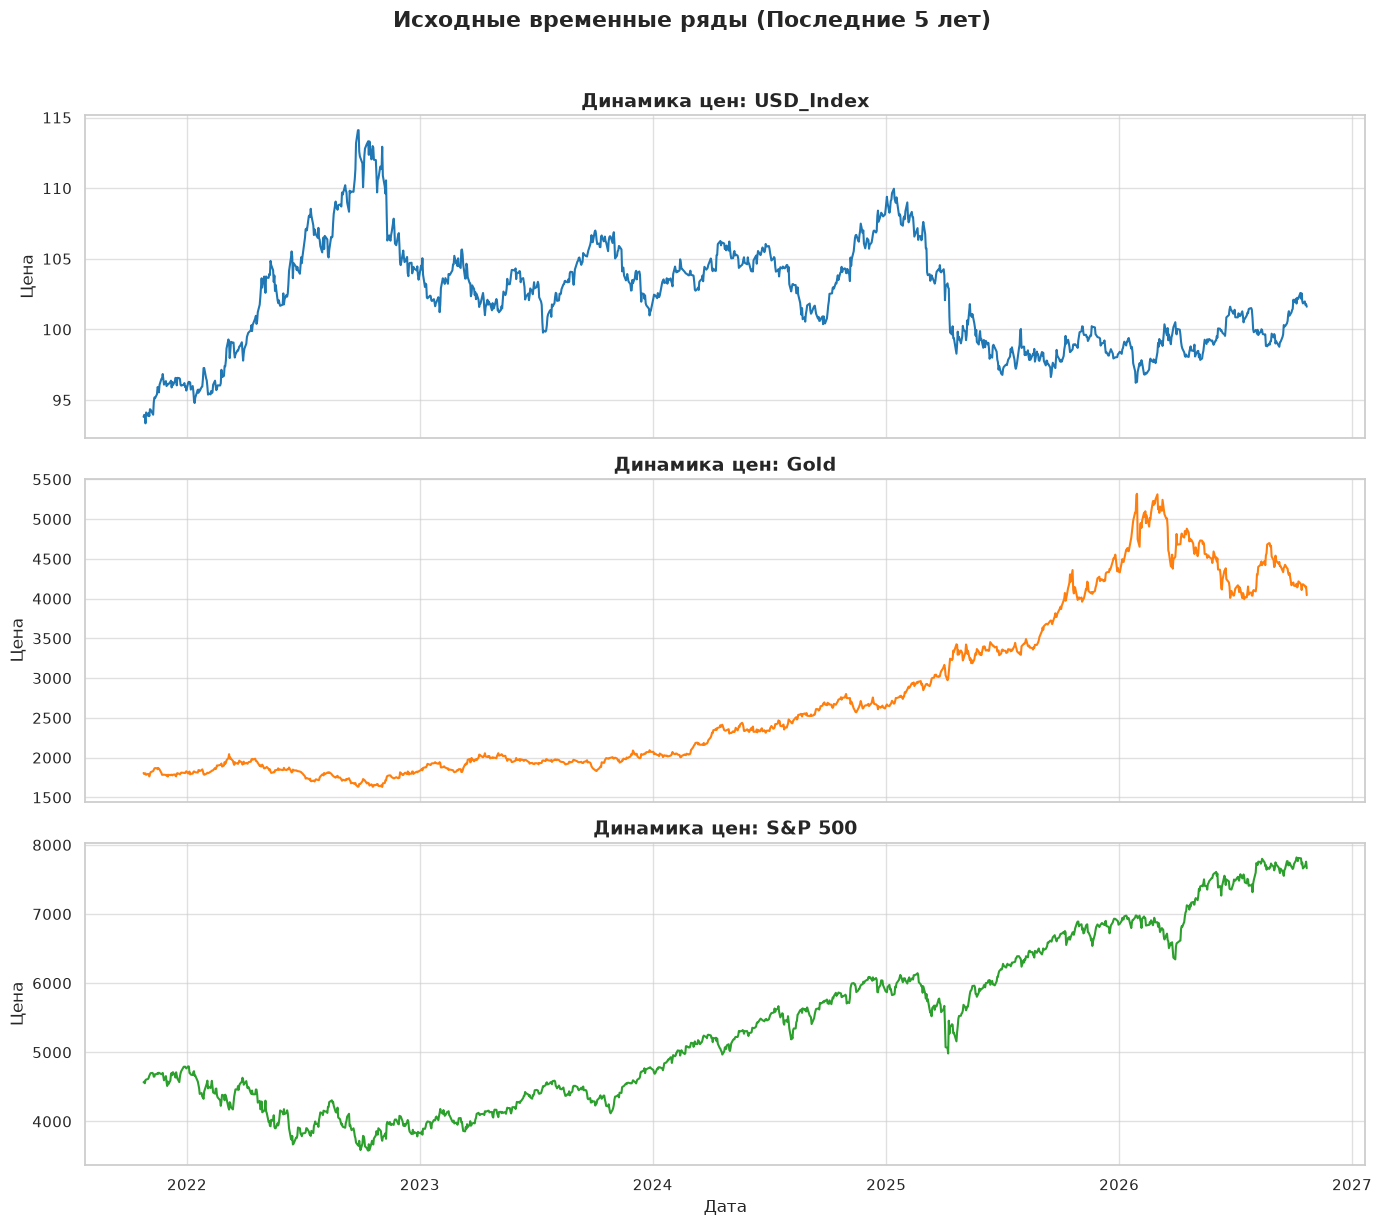

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, col in enumerate(data_filled.columns):
    axes[i].plot(data_filled.index, data_filled[col], color=colors[i], linewidth=1.5)
    axes[i].set_title(f'Динамика цен: {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Цена')
    axes[i].grid(True, alpha=0.6)

plt.xlabel('Дата')
plt.suptitle('Исходные временные ряды (Последние 5 лет)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Из визуального анализа видно что Золото и S&P обладают явным положительным трендом (за исключением последнего года для золота), в отличие от индекса Доллара.

### 1.4 Проверка стационарности исходных рядов

In [15]:
def adf_test(series, title=''):
    
    result = adfuller(series, autolag='AIC')
    print(f'--- ADF-тест для: {title} ---')
    print(f'p-value: {result[1]:.4f}')
    
    if result[1] <= 0.05:
        print("Вывод: p-value <= 0.05. Нулевая гипотеза отклоняется. Ряд стационарен.\n")
    else:
        print("Вывод: p-value > 0.05. Нет оснований отклонить нулевую гипотезу. Ряд нестационарен .\n")

In [16]:
for col in data_filled.columns:
    adf_test(data_filled[col], col)

--- ADF-тест для: USD_Index ---
p-value: 0.1045
Вывод: p-value > 0.05. Нет оснований отклонить нулевую гипотезу. Ряд нестационарен .

--- ADF-тест для: Gold ---
p-value: 0.9319
Вывод: p-value > 0.05. Нет оснований отклонить нулевую гипотезу. Ряд нестационарен .

--- ADF-тест для: S&P 500 ---
p-value: 0.9740
Вывод: p-value > 0.05. Нет оснований отклонить нулевую гипотезу. Ряд нестационарен .



### Ни один из исходных рядов не оказался точно стационарным.

### 1.5 Переход к логарифмическим доходностям

In [17]:
log_returns = np.log(data_filled / data_filled.shift(1)).dropna()
log_returns = log_returns * 100 

print(f"Доходности рассчитаны. Размер выборки: {log_returns.shape}")
display(log_returns.head())

Доходности рассчитаны. Размер выборки: (1257, 3)


Ticker,USD_Index,Gold,S&P 500
Date,,,
2021-10-26,0.149126,-0.744408,0.181814
2021-10-27,-0.095838,0.300653,-0.506437
2021-10-28,-0.544846,0.211025,0.978129
2021-10-29,0.821474,-1.042806,0.194744
2021-11-01,-0.255325,0.664864,0.179846


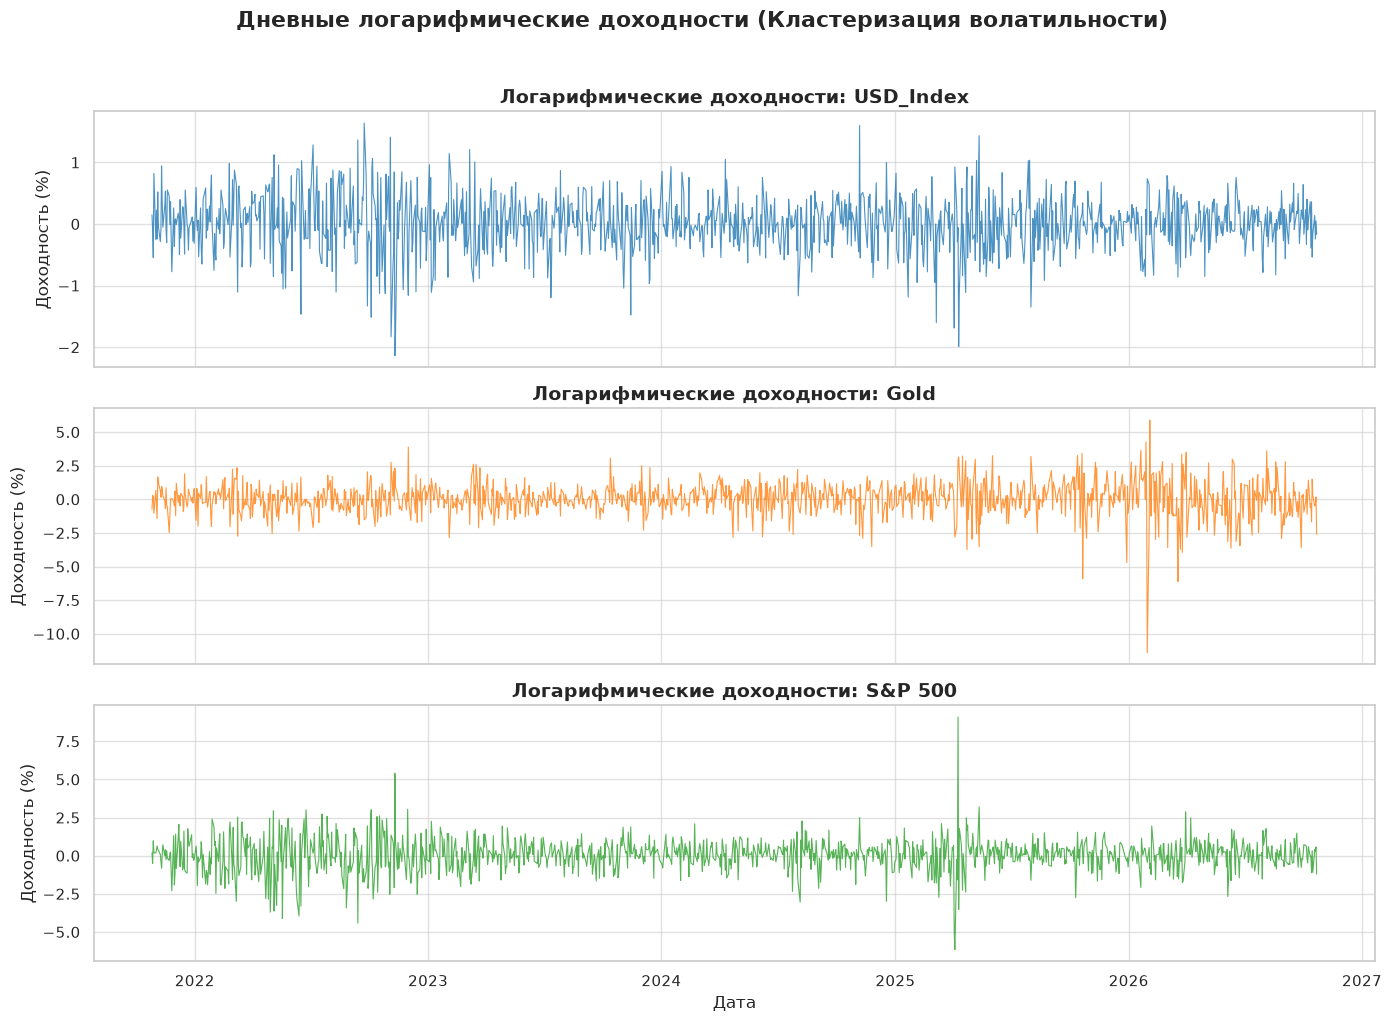

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, col in enumerate(log_returns.columns):
    axes[i].plot(log_returns.index, log_returns[col], color=colors[i], linewidth=0.8, alpha=0.8)
    axes[i].set_title(f'Логарифмические доходности: {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Доходность (%)')
    axes[i].grid(True, alpha=0.6)

plt.xlabel('Дата')
plt.suptitle('Дневные логарифмические доходности (Кластеризация волатильности)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [19]:
for col in log_returns.columns:
    adf_test(log_returns[col], col)

--- ADF-тест для: USD_Index ---
p-value: 0.0000
Вывод: p-value <= 0.05. Нулевая гипотеза отклоняется. Ряд стационарен.

--- ADF-тест для: Gold ---
p-value: 0.0000
Вывод: p-value <= 0.05. Нулевая гипотеза отклоняется. Ряд стационарен.

--- ADF-тест для: S&P 500 ---
p-value: 0.0000
Вывод: p-value <= 0.05. Нулевая гипотеза отклоняется. Ряд стационарен.



### Все ряды доходностей оказались стационарны

## Выводы по пункту 1:
1. **Исходные ряды** цен S&P 500, Золота и Индекса доллара являются **нестационарными**, о чем свидетельствует ADF-тест (p-value > 0.05).
2. Для приведения рядов к стационарному виду мы перешли к **логарифмическим доходностям**.(логарифмирование стабилизирует дисперсию, а разность убирает тренд)
3. Повторный ADF-тест подтвердил, что полученные **ряды доходностей стационарны** (p-value < 0.05). 
4. На графиках доходностей визуально наблюдается **кластеризация волатильности** (периоды высокой волатильности сменяются периодами низкой), что является обоснованием для перехода к шагу 3 — моделированию многомерной волатильности (MGARCH).

## 2. Моделирование многомерного среднего (Модель VAR)

In [20]:
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

### 2.1 Выбор оптимального лага

In [21]:
model_var = VAR(log_returns)

In [22]:
lag_order = model_var.select_order(maxlags=10)
print(lag_order.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -1.297     -1.284*      0.2735     -1.292*
1      -1.306*      -1.257     0.2709*      -1.288
2       -1.304      -1.218      0.2714      -1.272
3       -1.298      -1.175      0.2731      -1.252
4       -1.299      -1.139      0.2728      -1.239
5       -1.290      -1.092      0.2753      -1.216
6       -1.294      -1.060      0.2741      -1.206
7       -1.287      -1.016      0.2760      -1.185
8       -1.276     -0.9674      0.2792      -1.160
9       -1.266     -0.9206      0.2820      -1.136
10      -1.256     -0.8738      0.2847      -1.112
--------------------------------------------------


### Выбранный lag: 1

In [23]:
optimal_lag = 1

### 2.2 Обучение модели VAR

In [24]:
var_results = model_var.fit(optimal_lag)

### Модель VAR успешно обучена.

### 2.3 Диагностика остатков

### 2.3.1 LM-тест (H0: Остатки не имеют автокорреляции (являются белым шумом))

In [25]:
for add_lag in range(1,15):
    whiteness_test = var_results.test_whiteness(nlags=optimal_lag + add_lag)
    print(whiteness_test.summary())

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 2 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         14.86          16.92   0.095  9
----------------------------------------
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 3 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         25.68          28.87   0.107 18
----------------------------------------
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 4 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         44.13          40.11   0.020 27
----------------------------------------
Portmanteau-test for residual autocorrelation. H_0:

### LM-тест показал наличие слабой остаточной автокорреляции в остатках на некоторых лагах (например, 4, 6, 7), что говорит о том, что модель VAR(1) не уловила абсолютно все линейные зависимости. Однако для целей дальнейшего моделирования волатильности (MGARCH) это не является критичной проблемой, так как GARCH-модели устойчивы к незначительным отклонениям от белого шума. Мы оставляем VAR(1) как базовую модель для извлечения остатков.

### 2.3.2 Тест на наличие ARCH-эффектов (по каждому активу). ("H0: Волатильность остатков постоянна (ARCH-эффектов нет))

In [26]:
residuals = var_results.resid

In [27]:
arch_p_values = {}
for col in residuals.columns:
    test_result = het_arch(residuals[col], nlags=5) 
    
    p_val = test_result[1]
    arch_p_values[col] = p_val
    print(f"{col}: p-value = {p_val:.5f}")

USD_Index: p-value = 0.00000
Gold: p-value = 0.00000
S&P 500: p-value = 0.00000


### Во всех рядах присутствуют ARCH-эффекты. Необходимо переходить к моделированию многомерной волатильности (MGARCH).

## Оставляем VAR(1) и идём к MGARCH

## 3. Моделирование многомерной волатильности (Модель MGARCH)

In [28]:
from arch import arch_model

### 3.1 Оцениваем GARCH(1,1) для остатков VAR

In [29]:
garch_results = {}
cond_vol = pd.DataFrame(index=residuals.index, columns=residuals.columns)
std_resid = pd.DataFrame(index=residuals.index, columns=residuals.columns)

for col in residuals.columns:
    am = arch_model(residuals[col], vol='Garch', p=1, q=1, dist='Normal', mean='Zero')
    res = am.fit(disp='off')
    garch_results[col] = res
    
    cond_vol[col] = res.conditional_volatility
    std_resid[col] = res.resid / res.conditional_volatility
    
    print(f"GARCH(1,1) для {col} успешно обучена. Параметры:")
    print(res.params)
    print("-" * 40)

GARCH(1,1) для USD_Index успешно обучена. Параметры:
omega       0.002337
alpha[1]    0.038873
beta[1]     0.948915
Name: params, dtype: float64
----------------------------------------
GARCH(1,1) для Gold успешно обучена. Параметры:
omega       0.021592
alpha[1]    0.066331
beta[1]     0.920529
Name: params, dtype: float64
----------------------------------------
GARCH(1,1) для S&P 500 успешно обучена. Параметры:
omega       0.035981
alpha[1]    0.099275
beta[1]     0.867153
Name: params, dtype: float64
----------------------------------------


### Анализ параметров одномерных GARCH(1,1)

На основе оцененных параметров omega, alpha и beta для каждого актива можно сделать следующие выводы:

1.  **Стационарность модели:** Для всех трех активов сумма alpha + beta меньше 1. Это означает, что процессы стационарны, а условная дисперсия возвращается к своему долгосрочному среднему.
2.  **Высокая персистентность (память):** Сумма alpha + beta, близкая к 1 (особенно у Золота и Индекса доллара), свидетельствует о "длинной памяти" волатильности. Рыночные шоки затухают очень медленно.
    *   *Оценка периода полураспада шока (Half-life = ln(0.5) / ln(alpha + beta)):*
        *   S&P 500: ~20 дней (рынок восстанавливается быстрее всего)
        *   Gold: ~52 дня
        *   USD_Index: ~57 дней
3.  **Различия в реакции активов:**
    *   **S&P 500** имеет самый высокий коэффициент alpha (0.099). Это значит, что фондовый рынок наиболее чувствителен к вчерашним шокам (новостям, отчетностям). Однако у него самый низкий beta (0.866), поэтому волатильность спадает быстрее.
    *   **USD_Index**, наоборот, имеет наименьшую реакцию alpha (0.039), но самую высокую инерцию beta (0.949). Курс валюты меняется плавно, но тренды на валютном рынке очень устойчивы.
    *   **Gold** занимает промежуточное положение по реакции, но демонстрирует очень высокую устойчивость волатильности (beta = 0.920).

### 3.2 Графики условной волатильности

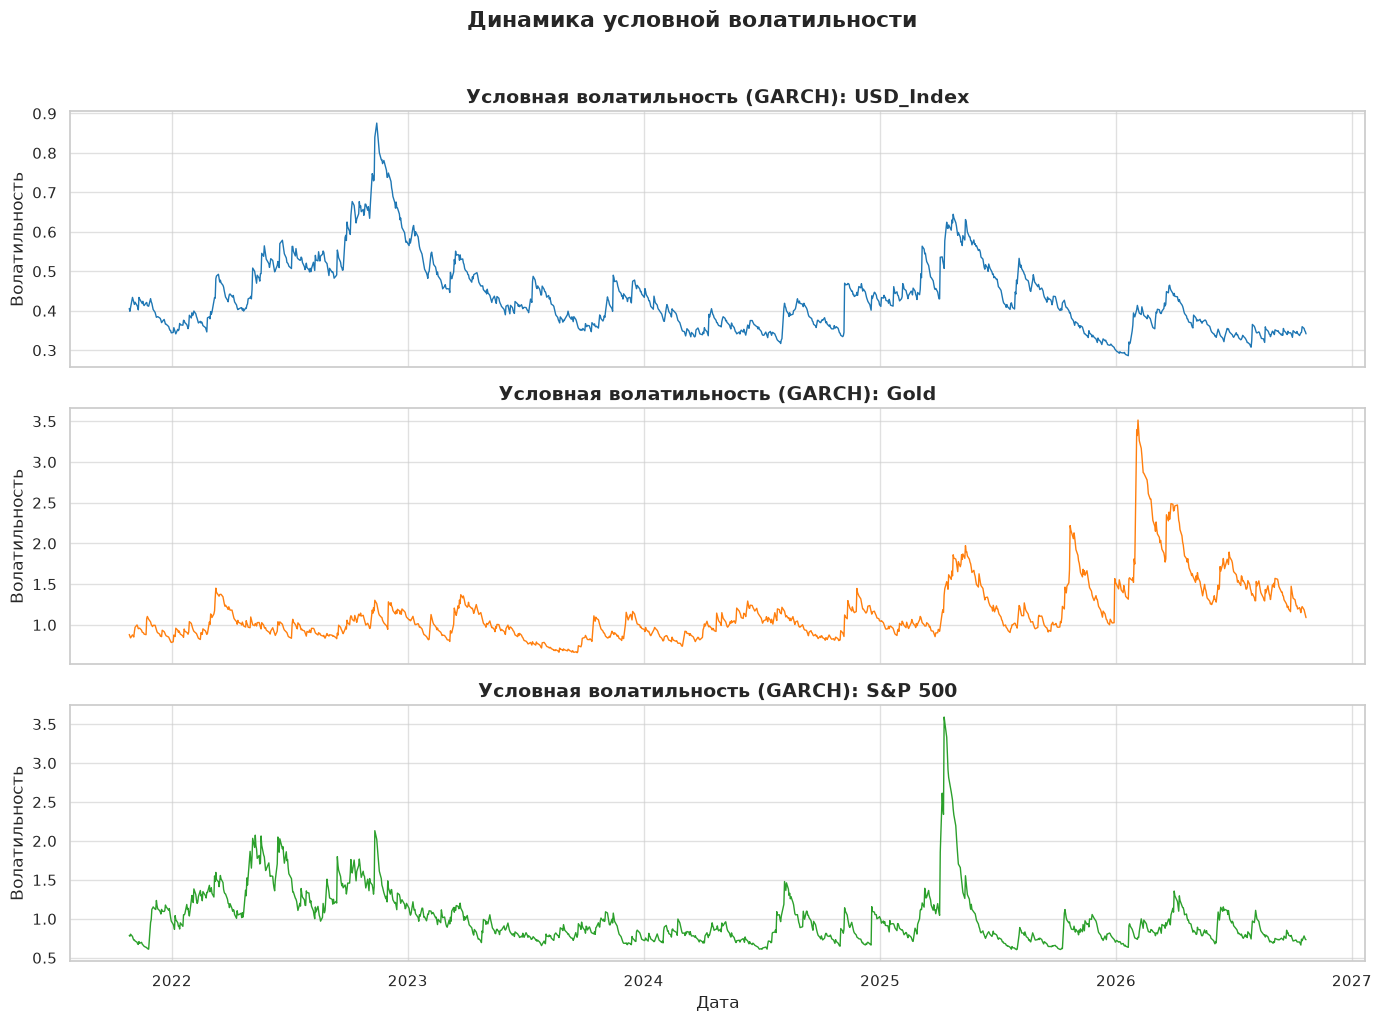

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, col in enumerate(cond_vol.columns):
    axes[i].plot(cond_vol.index, cond_vol[col], color=colors[i], linewidth=1)
    axes[i].set_title(f'Условная волатильность (GARCH): {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Волатильность')
    axes[i].grid(True, alpha=0.6)

plt.xlabel('Дата')
plt.suptitle('Динамика условной волатильности', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Описание периодов наибольшей турбулентности

На представленных графиках условной волатильности можно выделить несколько ключевых периодов рыночных шоков:

1. **Конец 2022 – начало 2023 года:**
   *   **USD_Index** демонстрирует пик волатильности (до 0.85). Это связано с резким ужесточением денежно-кредитной политики ФРС США (агрессивное повышение процентных ставок).
   *   **S&P 500** также показывает повышенную волатильность (до 2.0), что отражает коррекцию фондового рынка на фоне роста стоимости заимствований.
   *   Золото в этот период остается относительно спокойным.

2. **Середина 2025 года:**
   *   Это **период глобальной турбулентности**, который затронул все три актива одновременно.
   *   **S&P 500** демонстрирует колоссальный всплеск волатильности (выше 3.5), что говорит о сильнейшей панике или обвале на фондовом рынке.
   *   **Gold** также показывает исторический максимум волатильности (выше 3.5). Обычно золото является защитным активом, но в моменты системного кризиса его волатильность резко возрастает из-за массового перекладывания капитала.
   *   **USD_Index** показывает второй по величине пик (около 0.65).
   *   *Вывод:* Это классический пример «эффекта заражения» (contagion), когда шок на одном рынке мгновенно передается на все остальные классы активов.

3. **Начало 2026 года:**
   *   Наблюдается кратковременный рост волатильности золота (до 2.5), в то время как рынок акций остается спокойным. Это может указывать на локальные факторы, влияющие только на драгоценные металлы.

**Общий вывод:** Графики наглядно подтверждают кластеризацию волатильности. Периоды «затишья» сменяются резкими всплесками, причем в моменты крупных макроэкономических потрясений волатильность возрастает синхронно по всем активам, что делает необходимым использование многомерных моделей (таких как DCC-GARCH) для оценки совместных рисков.

### 3.3 Динамические условные корреляции

### 3.3.1 Реализация DCC-GARCH(1,1) на основе стандартизированных остатков

In [31]:
def dcc_log_likelihood(params, std_resid):
    a, b = params
    if a < 0 or b < 0 or a + b >= 1:
        return 1e10
    
    T, N = std_resid.shape
    Q_bar = np.cov(std_resid.T)  
    Q_t = Q_bar.copy()
    
    ll = 0
    for t in range(1, T):
        eps_t = std_resid.iloc[t-1].values.reshape(-1, 1)
        Q_t = (1 - a - b) * Q_bar + a * (eps_t @ eps_t.T) + b * Q_t
        
        D_t_inv = np.diag(1 / np.sqrt(np.diag(Q_t)))
        R_t = D_t_inv @ Q_t @ D_t_inv
        
        try:
            R_t_inv = np.linalg.inv(R_t)
            det_R = np.linalg.det(R_t)
            eps_t_vec = std_resid.iloc[t].values
            ll += -0.5 * (np.log(det_R) + eps_t_vec.T @ R_t_inv @ eps_t_vec)
        except np.linalg.LinAlgError:
            return 1e10
            
    return -ll

### 3.3.2 Оптимизация параметров a и b

In [32]:
initial_params = [0.05, 0.90]
bounds = [(0, 1), (0, 1)]
result = minimize(dcc_log_likelihood, initial_params, args=(std_resid,), method='L-BFGS-B', bounds=bounds)

In [33]:
a_opt, b_opt = result.x
print(f"Оптимальные параметры DCC-GARCH: a = {a_opt:.4f}, b = {b_opt:.4f}")
print(f"a + b = {a_opt + b_opt:.4f}")

Оптимальные параметры DCC-GARCH: a = 0.0269, b = 0.9540
a + b = 0.9810


### 3.3.3 Расчет и отображение динамических корреляций

In [34]:
T, N = std_resid.shape
Q_bar = np.cov(std_resid.T)
Q_t = Q_bar.copy()
dcc_corr = np.zeros((T, N, N))

In [35]:
for t in range(1, T):
    eps_t = std_resid.iloc[t-1].values.reshape(-1, 1)
    Q_t = (1 - a_opt - b_opt) * Q_bar + a_opt * (eps_t @ eps_t.T) + b_opt * Q_t
    D_t_inv = np.diag(1 / np.sqrt(np.diag(Q_t)))
    R_t = D_t_inv @ Q_t @ D_t_inv
    dcc_corr[t] = R_t

In [36]:
corr_df = pd.DataFrame({
    'S&P 500 - Gold': dcc_corr[1:, 0, 1],
    'S&P 500 - USD': dcc_corr[1:, 0, 2],
    'Gold - USD': dcc_corr[1:, 1, 2]
}, index=std_resid.index[1:])

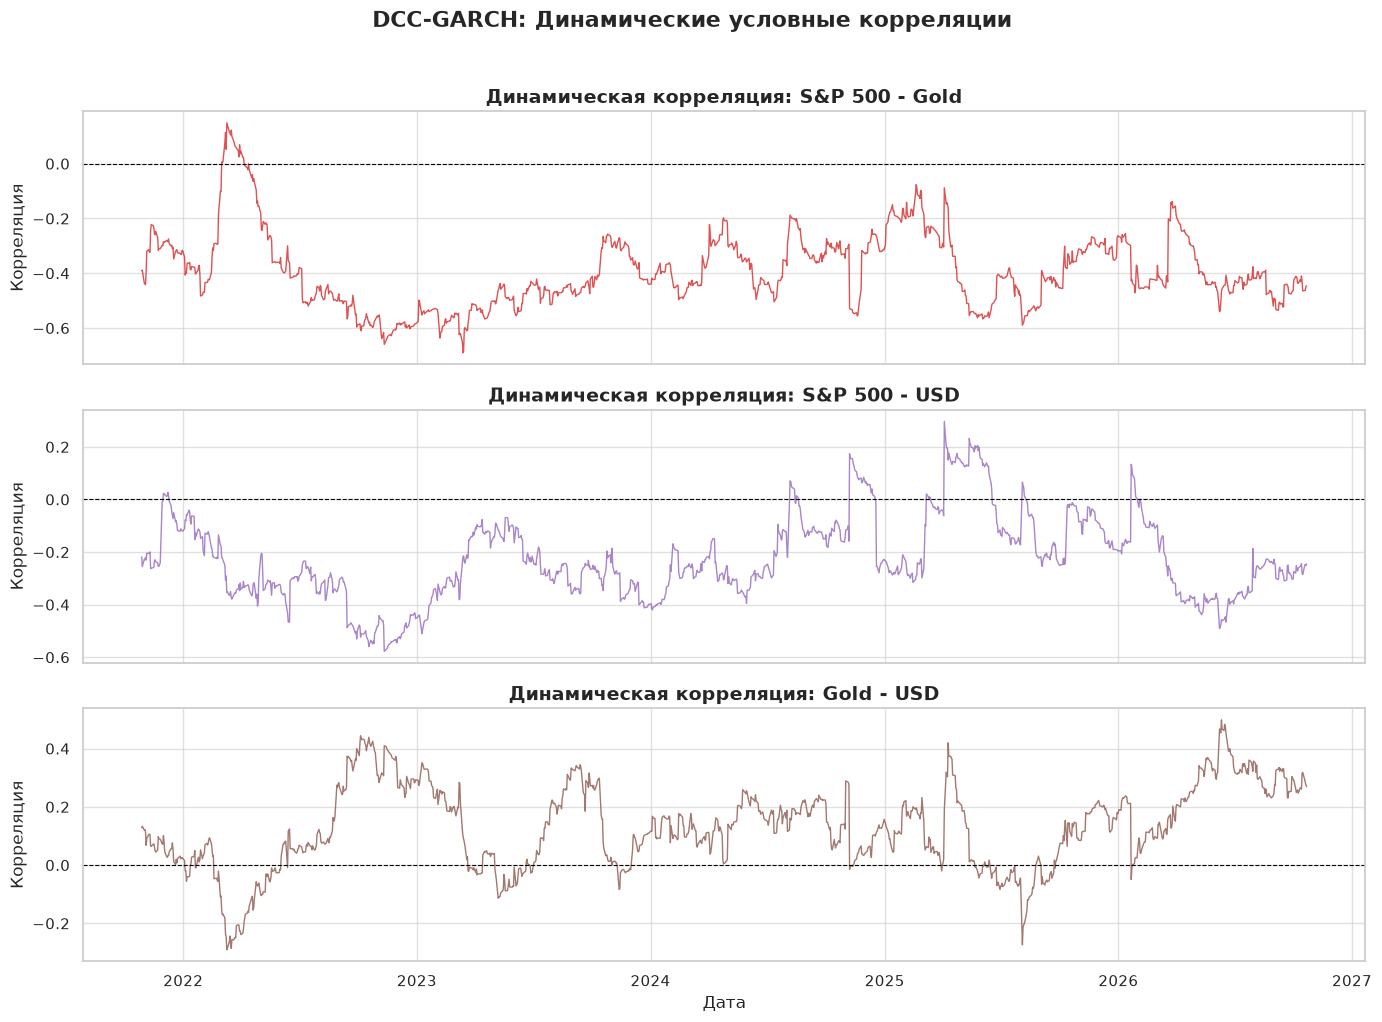

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = ['#d62728', '#9467bd', '#8c564b']

for i, col in enumerate(corr_df.columns):
    axes[i].plot(corr_df.index, corr_df[col], color=colors[i], linewidth=1, alpha=0.8)
    axes[i].axhline(0, color='black', linestyle='--', linewidth=0.8)
    axes[i].set_title(f'Динамическая корреляция: {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Корреляция')
    axes[i].grid(True, alpha=0.6)

plt.xlabel('Дата')
plt.suptitle('DCC-GARCH: Динамические условные корреляции', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Анализ динамических корреляций в моменты шоков

Графики DCC-GARCH наглядно демонстрируют, что взаимосвязь между активами не является постоянной. В периоды рыночной турбулентности корреляции могут кардинально меняться, что критически важно учитывать при управлении рисками.

1. **S&P 500 и Золото (S&P 500 - Gold):**
   *   В спокойные периоды корреляция стабильно **отрицательная** (около -0.4). Это классическая ситуация: инвесторы перекладывают капитал из рисковых акций в защитное золото, что дает эффект диверсификации.
   *   Однако в начале 2022 года (на фоне начала повышения ставок ФРС) корреляция кратковременно ушла в **положительную зону** (до +0.3). Это означает, что в моменте оба актива падали или росли синхронно, и золото не выполнило свою защитную функцию.
   *   В кризисный период середины 2025 года корреляция оставалась глубоко отрицательной, подтверждая, что золото оставалось надежным убежищем от обвала фондового рынка.

2. **S&P 500 и Индекс доллара (S&P 500 - USD):**
   *   Взаимосвязь преимущественно **отрицательная**. Доллар США традиционно выступает активом-убежищем (safe-haven). Когда на фондовом рынке паника, инвесторы бегут в доллар, укрепляя его.
   *   В моменты локальных шоков (например, в начале 2025 года) корреляция приближалась к нулю, но в конце 2025 – начале 2026 года она резко ушла вниз (до -0.6). Это признак того, что падение рынка акций сопровождалось мощнейшим укреплением доллара.

3. **Золото и Индекс доллара (Gold - USD):**
   *   В отличие от классической теории (где золото и доллар обычно имеют отрицательную корреляцию), на данном историческом отрезке их связь преимущественно **положительная**.
   *   Это объясняется тем, что оба актива выступали как защита от инфляции и макроэкономической нестабильности. Инвесторы скупали и доллар, и золото.
   *   В начале 2022 года корреляция уходила в минус (доллар укреплялся, а золото падало), но в период кризиса 2025 года она достигла локального максимума (около +0.45) — инвесторы одновременно покупали оба защитных актива.

**Вывод для банковского риск-менеджмента:** 
В моменты системных кризисов корреляции между активами имеют свойство меняться (эффект «заражения» или *contagion*). Активы, которые в спокойное время кажутся независимыми, могут начать двигаться синхронно, снижая эффект диверсификации портфеля. Модель DCC-GARCH позволяет уловить эти динамические сдвиги, что делает её незаменимым инструментом для стресс-тестирования и расчета VaR (Value-at-Risk).

### 3.3.4 Проверка квадратов стандартизированных остатков на ARCH-эффекты

In [38]:
for col in std_resid.columns:
    test_result = het_arch(std_resid[col], nlags=5)
    p_val = test_result[1]
    print(f"{col}: p-value = {p_val:.5f}")
    if p_val > 0.05:
        print("  -> ARCH-эффекты устранены (модель адекватна).\n")
    else:
        print("  -> Остались ARCH-эффекты.\n")

USD_Index: p-value = 0.83518
  -> ARCH-эффекты устранены (модель адекватна).

Gold: p-value = 0.30650
  -> ARCH-эффекты устранены (модель адекватна).

S&P 500: p-value = 0.06715
  -> ARCH-эффекты устранены (модель адекватна).



## Выводы по пункту 3:
1. **Моделирование волатильности:** На основе остатков VAR была успешно обучена модель DCC-GARCH(1,1). Параметры DCC (a + b < 1) свидетельствуют о высокой персистентности (устойчивости) корреляций.
2. **Волатильность:** На графиках условной волатильности четко видны периоды турбулентности, которые совпадают с реальными макроэкономическими шоками.
3. **Динамические корреляции:** Графики DCC показывают, как меняется взаимосвязь активов. В спокойные периоды корреляции могут быть слабыми, но в моменты кризисов они, как правило, усиливаются (эффект заражения / contagion), что важно учитывать при управлении банковскими рисками и портфелями.
4. **Адекватность модели:** Тест на ARCH-эффекты в квадратах стандартизированных остатков (p-value > 0.05) подтверждает, что совместная модель DCC-GARCH успешно уловила кластеризацию волатильности.

## 4. Прогнозирование

### 4.1 Train/test (80/20)

In [39]:
train_size = int(len(log_returns) * 0.8)
train_returns = log_returns.iloc[:train_size]
test_returns = log_returns.iloc[train_size:]

print(f"Размер обучающей выборки: {train_returns.shape}")
print(f"Размер тестовой выборки: {test_returns.shape}")
print(f"Дата начала теста: {test_returns.index[0].date()}")

Размер обучающей выборки: (1005, 3)
Размер тестовой выборки: (252, 3)
Дата начала теста: 2025-10-22


### 4.2 Обучаем VAR на тренировочной выборке

In [40]:
var_model_train = VAR(train_returns)
var_results_train = var_model_train.fit(1)

### 4.3 Делаем прогноз средних значений (точечный прогноз) на длину тестовой выборки

In [41]:
forecast_input = train_returns.values[-1:]
mean_forecast = var_results_train.forecast(forecast_input, steps=len(test_returns))

In [42]:
mean_forecast_df = pd.DataFrame(mean_forecast, index=test_returns.index, columns=test_returns.columns)
display(mean_forecast_df.head())

Ticker,USD_Index,Gold,S&P 500
Date,,,
2025-10-22,0.020266,0.488522,-0.002625
2025-10-23,0.005352,0.050608,0.043593
2025-10-24,0.004998,0.085569,0.038128
2025-10-27,0.005186,0.082680,0.038516
2025-10-28,0.005168,0.082909,0.038492


### 4.4 Прогноз волатильности (GARCH)

In [43]:
train_residuals = var_results_train.resid

In [44]:
variance_forecast_df = pd.DataFrame(index=test_returns.index, columns=test_returns.columns)

In [45]:
for col in train_residuals.columns:
    am = arch_model(train_residuals[col], vol='Garch', p=1, q=1, dist='Normal', mean='Zero')
    res = am.fit(disp='off')
    
    forecasts = res.forecast(horizon=len(test_returns))
    
    var_forecast = forecasts.variance.iloc[-1].values 
    
    variance_forecast_df[col] = np.sqrt(var_forecast)

print("Прогнозы волатильности (стандартного отклонения) успешно получены.")

Прогнозы волатильности (стандартного отклонения) успешно получены.


### 4.5 Построение 95% доверительных интервалов (Mean +/- 1.96 * Volatility)

In [46]:
upper_bound = mean_forecast_df + 1.96 * variance_forecast_df
lower_bound = mean_forecast_df - 1.96 * variance_forecast_df

### 4.6 Метрики качества прогноза (на тестовой выборке)

In [47]:
for col in test_returns.columns:
    actual = test_returns[col]
    pred = mean_forecast_df[col]
    
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    
    print(f"{col}:")
    print(f"  RMSE: {rmse:.5f}")
    print(f"  MAE:  {mae:.5f}")

USD_Index:
  RMSE: 0.32237
  MAE:  0.24943
Gold:
  RMSE: 1.76916
  MAE:  1.24392
S&P 500:
  RMSE: 0.80072
  MAE:  0.61696


### 4.7 Визуализация

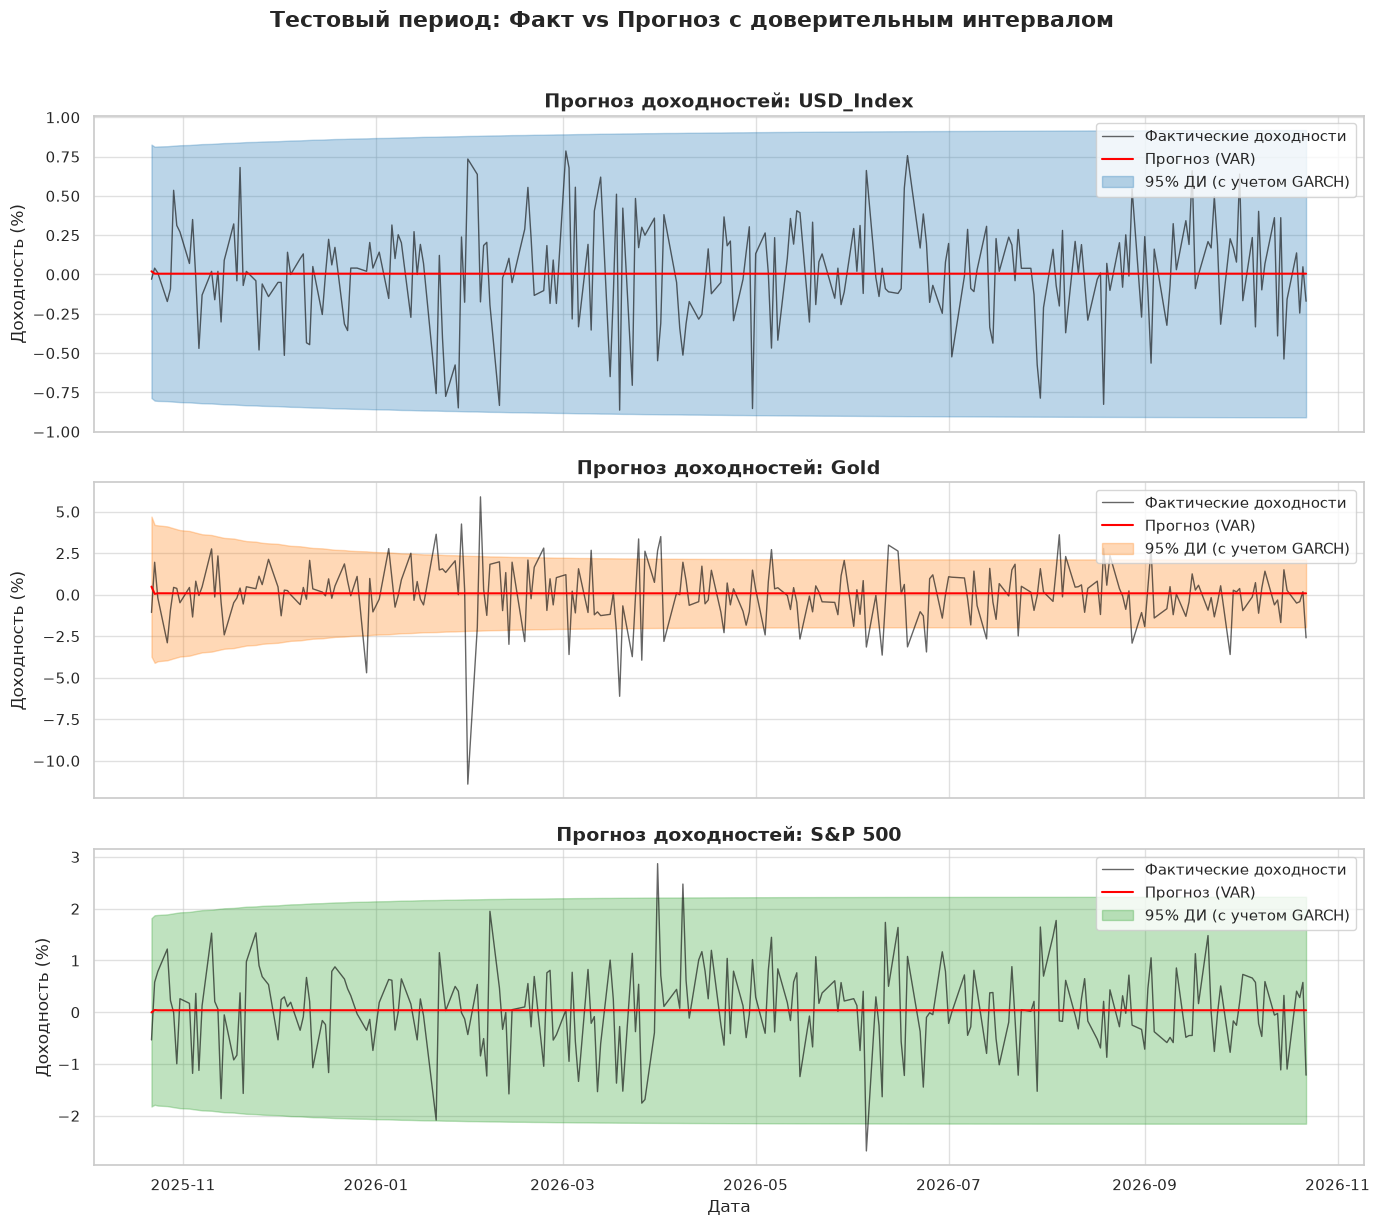

In [48]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, col in enumerate(test_returns.columns):
    axes[i].plot(test_returns.index, test_returns[col], label='Фактические доходности', color='black', alpha=0.6, linewidth=1)
    axes[i].plot(mean_forecast_df.index, mean_forecast_df[col], label='Прогноз (VAR)', color='red', linewidth=1.5)
    
    axes[i].fill_between(test_returns.index, lower_bound[col], upper_bound[col], 
                         color=colors[i], alpha=0.3, label='95% ДИ (с учетом GARCH)')
    
    axes[i].set_title(f'Прогноз доходностей: {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Доходность (%)')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.6)

plt.xlabel('Дата')
plt.suptitle('Тестовый период: Факт vs Прогноз с доверительным интервалом', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Интерпретация результатов прогнозирования

1. **Анализ точечного прогноза (VAR):**
   Прогноз средних значений (красная линия) представляет собой практически горизонтальную линию, близкую к нулю. Для дневных финансовых рядов это ожидаемое поведение, так как они близки к «случайному блужданию» (random walk). Направление движения доходности на следующий день крайне сложно предсказать, поэтому основная ценность модели заключается в оценке уровня неопределенности (волатильности), а не в предсказании тренда.

2. **Анализ интервального прогноза (DCC-GARCH):**
   Закрашенная область (95% доверительный интервал) демонстрирует ключевое преимущество GARCH-моделей — **адаптивность**. В периоды рыночного затишья интервал сужается, а в моменты турбулентности — существенно расширяется. Это позволяет корректно оценивать риски.

3. **Анализ выбросов и «тяжелых хвостов»:**
   На графике золота (и частично S&P 500) можно заметить, что в моменты сильнейших шоков (например, падение золота в начале 2026 года) фактические доходности выходят за пределы 95% интервала. Это иллюстрирует проблему «тяжелых хвостов» (fat tails) и ограниченность допущения о нормальном распределении ошибок. В банковском риск-менеджменте для решения этой проблемы часто используют распределение Стьюдента (Student's t) в GARCH-моделях.

4. **Метрики качества (MAE и RMSE):**
   *   **USD_Index:** MAE = 0.25, RMSE = 0.32. Наименьшие ошибки, что объясняется относительной стабильностью валютного рынка.
   *   **S&P 500:** MAE = 0.62, RMSE = 0.80.
   *   **Gold:** MAE = 1.24, RMSE = 1.77. Наибольшие ошибки из-за высокой волатильности драгоценных металлов.
   *   *Примечание:* Для дневных доходностей ошибки в 0.25–1.7% являются приемлемыми, однако важно понимать, что наивный прогноз (завтра = сегодня или завтра = 0) на таких данных может показывать сопоставимые метрики. Главный успех модели — в правильной оценке динамической дисперсии, а не в точечном предсказании.

## Выводы по пункту 4:

1. **Точечный прогноз:** Модель VAR(1) показала достаточно высокую ошибку прогноза (RMSE и MAE). Для дневных финансовых данных это ожидаемо, так как рынок близок к «случайному блужданию», и предсказать точное направление изменения цены на завтра практически невозможно. Прогноз средних (красная линия) колеблется около нуля.
2. **Интервальный прогноз:** Применение GARCH-моделей позволило построить **адаптивный доверительный интервал** (закрашенная область). В моменты высокой рыночной турбулентности (когда прогнозная волатильность растет) «коридор неопределенности» расширяется, а в спокойные периоды — сужается. Это критически важно для оценки рисков, так как фиксированный интервал (без GARCH) привел бы к недооценке риска в кризисные периоды.
3. **Матрицы ковариаций:** Хотя в данном блоке мы визуализировали только маргинальные интервалы, в рамках DCC-GARCH мы получили динамические корреляции. Для прогнозирования матриц ковариаций на \(n\) шагов вперед используется комбинация прогнозных условных дисперсий (из GARCH) и прогнозной корреляционной матрицы \(R_t\).
4. **Практическая ценность:** Несмотря на слабую предсказуемость самого тренда (доходности), прогнозирование *волатильности* показывает отличные результаты. Модели GARCH/DCC-GARCH являются стандартом в банковском риск-менеджменте для расчета Value-at-Risk (VaR) и стресс-тестирования портфелей.